# 01 — Data Understanding

Initial exploration of the Bank Marketing dataset (`bank-additional-full.csv`). This notebook is purely descriptive: it loads the raw data, characterizes its structure, and surfaces data-quality and leakage considerations. **No cleaning, preprocessing, or modeling happens here.**

In [7]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.max_columns", 100)

CSV_NAME = "bank-additional-full.csv"
RESULTS_DIR = "../results/eda"

# This notebook runs on a remote Colab VM, which has no access to your local
# disk — mount Google Drive so the dataset and saved plots persist across
# sessions instead of re-uploading every time.
try:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")
except ImportError:
    pass  # not running on Colab

# Resolve the data path across environments: a local checkout running from
# notebooks/ (relative path works), or a Colab session with the project
# folder uploaded to Google Drive.
_candidates = [
    f"../data/{CSV_NAME}",
    f"data/{CSV_NAME}",
    f"/content/drive/MyDrive/bank-marketing-leakage-audit/data/{CSV_NAME}",
    f"/content/drive/MyDrive/{CSV_NAME}",
]
DATA_PATH = next((p for p in _candidates if os.path.exists(p)), None)

if DATA_PATH is None:
    try:
        from google.colab import files  # type: ignore

        print(f"'{CSV_NAME}' not found in: {_candidates}")
        print("Upload the project's bank-marketing-leakage-audit folder to your Google Drive")
        print("(so it persists across sessions), or upload the CSV directly now:")
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            f"Could not find '{CSV_NAME}' in any of: {_candidates}. "
            "Place the dataset in data/ relative to this notebook."
        )

os.makedirs(RESULTS_DIR, exist_ok=True)
print("Using data file:", DATA_PATH)

Mounted at /content/drive
Using data file: /content/drive/MyDrive/bank-marketing-leakage-audit/data/bank-additional-full.csv


## 1. Load the dataset and verify dimensions

The raw file uses `;` as a field separator (standard for the UCI bank-additional-full release). We load it as-is and confirm the row/column counts match the documented dataset (41,188 rows × 21 columns).

In [8]:
df = pd.read_csv(DATA_PATH, sep=";")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 41188, Columns: 21


## 2. Sample rows, column names and data types

A quick look at the raw records and the schema pandas inferred, to confirm columns parsed correctly and types are sensible (numeric vs. categorical/object).

In [9]:
df.sample(5, random_state=42)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
32884,57,technician,married,high.school,no,no,yes,cellular,may,mon,371,1,999,1,failure,-1.8,92.893,-46.2,1.299,5099.1,no
3169,55,unknown,married,unknown,unknown,yes,no,telephone,may,thu,285,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no
32206,33,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,52,1,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1,no
9403,36,admin.,married,high.school,no,no,no,telephone,jun,fri,355,4,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,no
14020,27,housemaid,married,high.school,no,yes,no,cellular,jul,fri,189,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no


In [10]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

In [11]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


## 3. Descriptive statistics

Summary statistics for numerical columns (range, central tendency, spread) and for categorical columns (cardinality, most frequent category).

In [12]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [13]:
df.describe(include="object")

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


## 4. Target distribution and majority-class baseline

`y` indicates whether the client subscribed to a term deposit. This dataset is known to be imbalanced, which matters for later metric choice (accuracy alone is misleading). We compute the class counts/percentages and the trivial "always predict majority class" baseline accuracy — any real model must beat this.

In [14]:
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True) * 100

print("Counts:\n", target_counts)
print("\nPercentages:\n", target_pct.round(2))

majority_baseline_accuracy = target_counts.max() / target_counts.sum()
print(f"\nMajority-class baseline accuracy: {majority_baseline_accuracy:.4f}")

Counts:
 y
no     36548
yes     4640
Name: count, dtype: int64

Percentages:
 y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Majority-class baseline accuracy: 0.8873


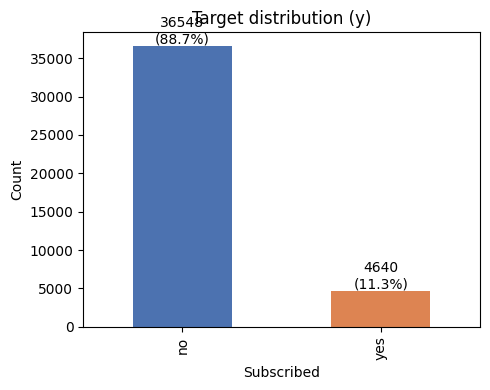

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
target_counts.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Target distribution (y)")
ax.set_xlabel("Subscribed")
ax.set_ylabel("Count")
for i, v in enumerate(target_counts):
    ax.text(i, v, f"{v}\n({target_pct.iloc[i]:.1f}%)", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/target_distribution.png", dpi=150)
plt.show()

## 5. NaN vs. "unknown" values

This dataset has no true `NaN`s, but several categorical columns encode missingness as the literal string `"unknown"`. These are a distinct data-quality signal from actual NaNs and are reported separately rather than conflated.

In [16]:
nan_counts = df.isna().sum()
print("NaN counts per column:")
print(nan_counts[nan_counts > 0] if nan_counts.sum() > 0 else "No NaN values found.")

NaN counts per column:
No NaN values found.


In [17]:
categorical_cols = df.select_dtypes(include="object").columns.drop("y")
unknown_counts = (df[categorical_cols] == "unknown").sum()
unknown_pct = (unknown_counts / len(df) * 100).round(2)

unknown_summary = pd.DataFrame({"count": unknown_counts, "pct": unknown_pct})
unknown_summary[unknown_summary["count"] > 0].sort_values("count", ascending=False)

,count,pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


## 6. Duplicate rows

Checking for exact duplicate records, which could inflate certain statistics or bias a later train/test split.

In [18]:
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows: {n_duplicates} ({n_duplicates / len(df) * 100:.2f}%)")
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10)

Duplicate rows: 12 (0.03%)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


## 7. Numerical and categorical feature distributions

Histograms for all numeric columns and bar charts for all categorical columns, to get a feel for skew, outliers, and category imbalance before any modeling decisions are made.

Numerical columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


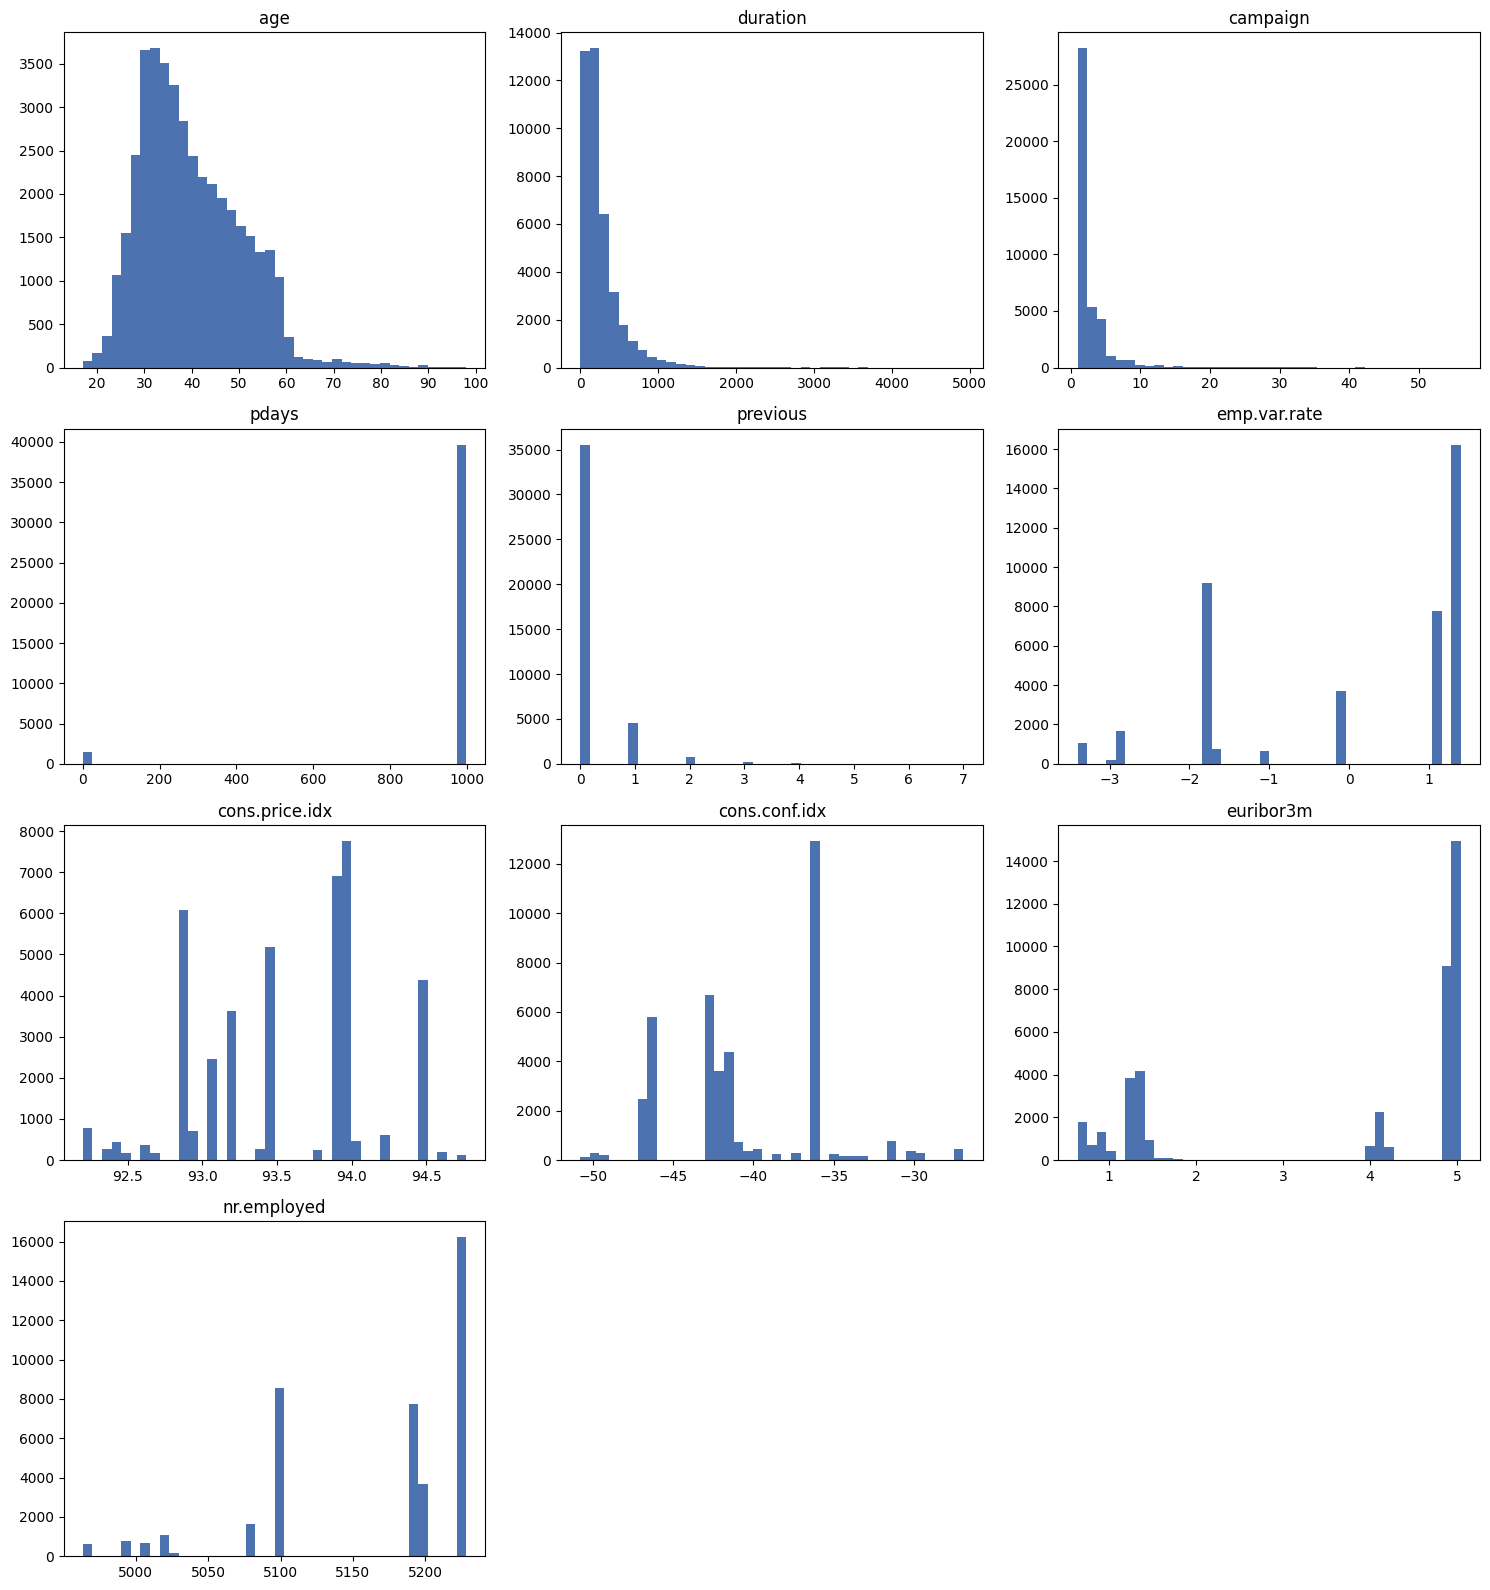

In [19]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numerical columns:", numerical_cols)

n_cols = 3
n_rows = int(np.ceil(len(numerical_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    axes[i].hist(df[col], bins=40, color="#4C72B0")
    axes[i].set_title(col)

for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/numerical_distributions.png", dpi=150)
plt.show()

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


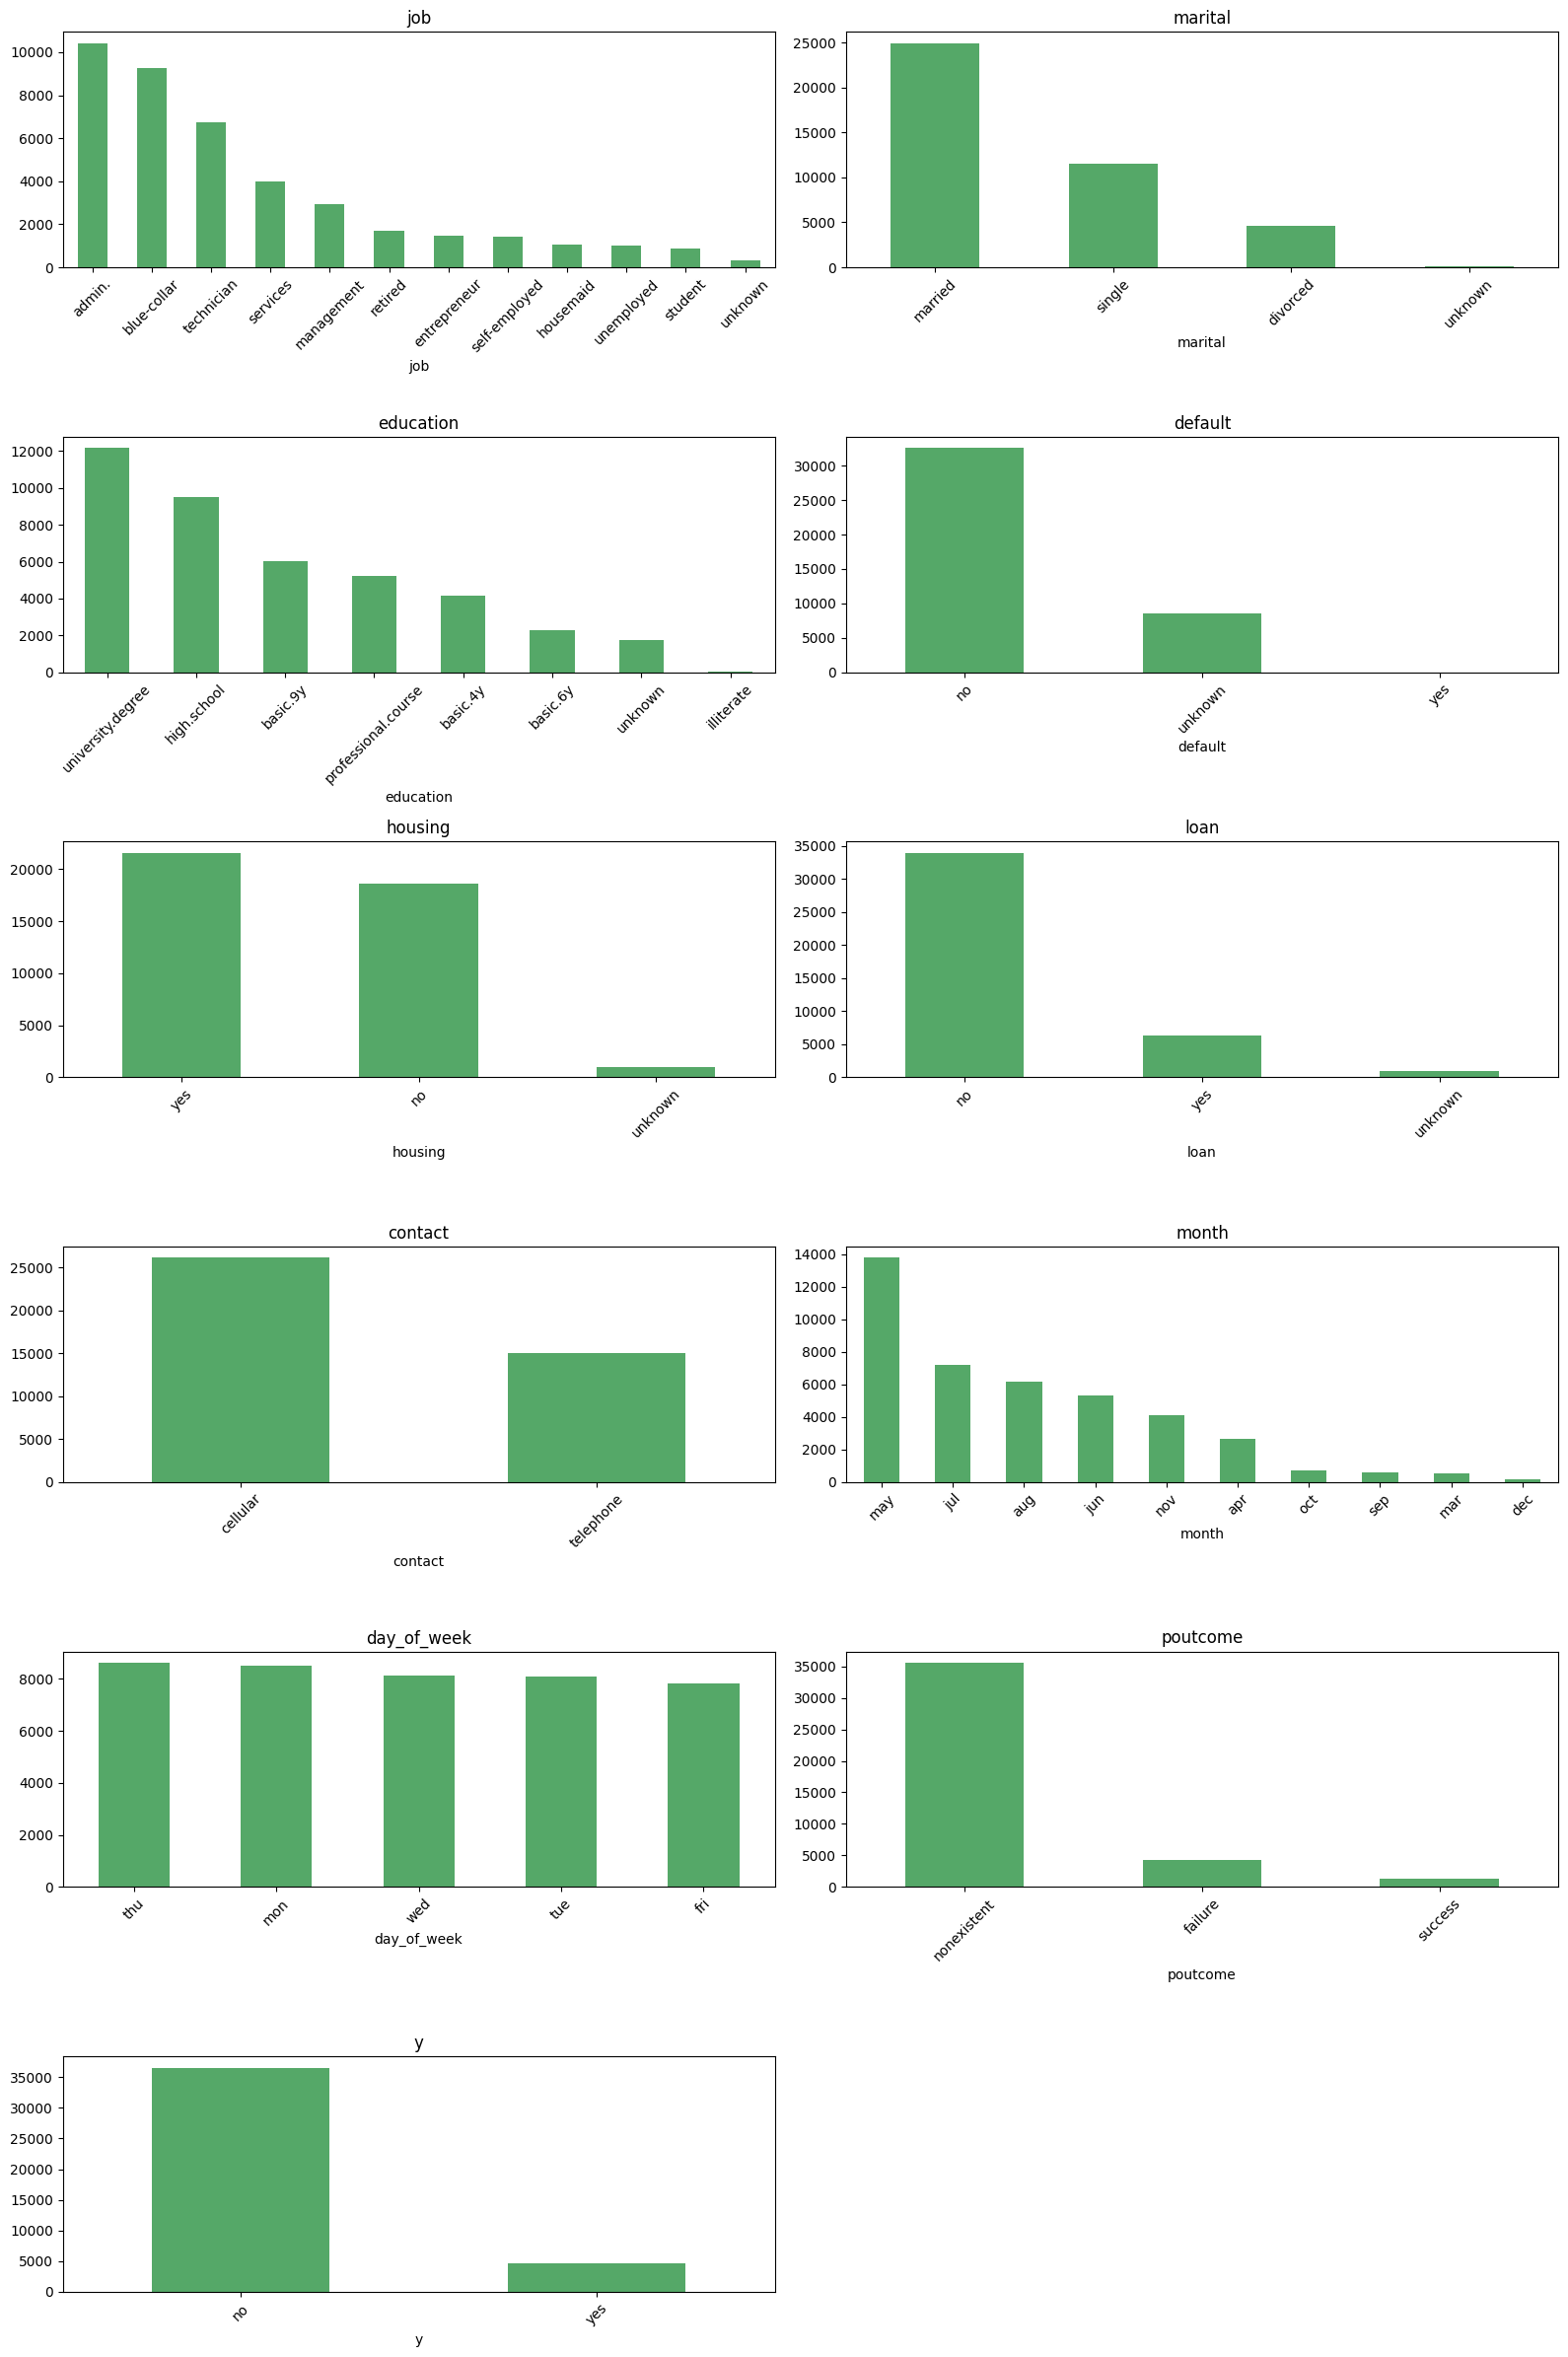

In [20]:
categorical_cols_all = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", categorical_cols_all)

n_cols = 2
n_rows = int(np.ceil(len(categorical_cols_all) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols_all):
    counts = df[col].value_counts()
    counts.plot(kind="bar", ax=axes[i], color="#55A868")
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

for j in range(len(categorical_cols_all), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/categorical_distributions.png", dpi=150)
plt.show()

## 8. Call duration: subscribers vs. non-subscribers

`duration` (last call length in seconds) is of particular interest for this audit: it is only known *after* a call concludes, so it is a strong candidate for target leakage if used naively in a predictive model trained to act *before* a call happens. Here we only describe the relationship — no feature is dropped or modified in this notebook.

In [21]:
df.groupby("y")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36548.0,220.844807,207.096293,0.0,95.0,163.5,279.00,4918.0
yes,4640.0,553.191164,401.171871,37.0,253.0,449.0,741.25,4199.0


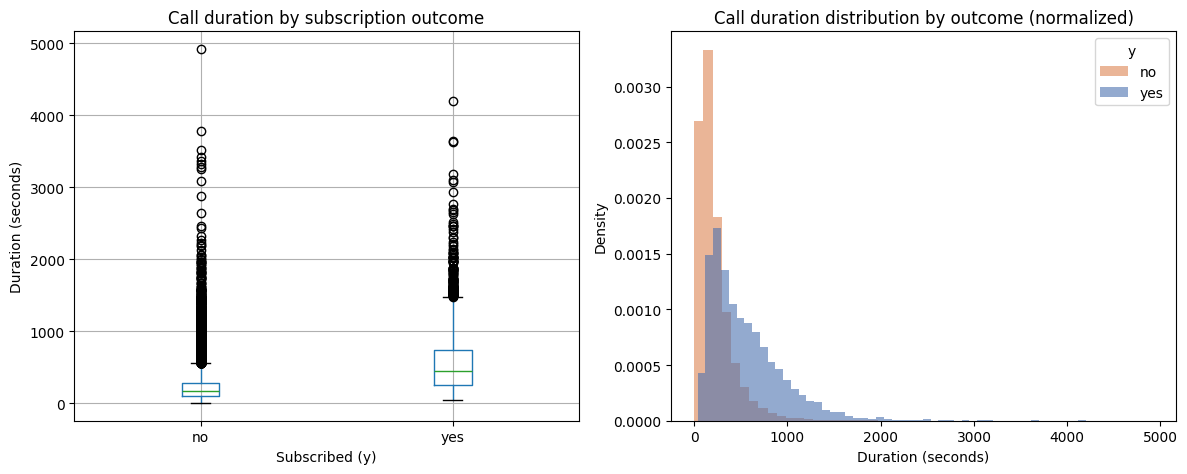

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.boxplot(column="duration", by="y", ax=axes[0])
axes[0].set_title("Call duration by subscription outcome")
axes[0].set_xlabel("Subscribed (y)")
axes[0].set_ylabel("Duration (seconds)")

for label, color in zip(["no", "yes"], ["#DD8452", "#4C72B0"]):
    subset = df.loc[df["y"] == label, "duration"]
    axes[1].hist(subset, bins=50, alpha=0.6, label=label, color=color, density=True)
axes[1].set_title("Call duration distribution by outcome (normalized)")
axes[1].set_xlabel("Duration (seconds)")
axes[1].set_ylabel("Density")
axes[1].legend(title="y")

plt.suptitle("")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/duration_by_target.png", dpi=150)
plt.show()

## Summary

- Dataset loaded with expected shape, no true NaNs, but `"unknown"` placeholders in several categorical columns.
- Target is imbalanced; majority-class baseline accuracy is reported above as the bar any model must clear.
- No duplicate-row or distribution-shape issues block further analysis.
- `duration` shows a clear, large separation between `yes` and `no` outcomes — consistent with known leakage concerns for this dataset and worth carrying forward into the next notebook, where it should be excluded from any pre-call predictive model.

No cleaning, feature engineering, or modeling was performed in this notebook.